# Лабораторная работа 1. Регрессия и метод главных компонент

## Введение

Цель работы: Изучить основы линейной регрессии, построить простейшие модели регрессии, провести обучение модели на реальных данных и оценить её качество.

В ходе работы проводится анализ и предобработка выбранного датасета, исследуется взаимосвязь между признаками и наличие мультиколлинеарности. Строятся модели линейной регрессии, Лассо и гребневой регрессии, оценивается их качество с помощью соответствующих метрик. Для снижения размерности данных и устранения мультиколлинеарности применяется метод главных компонент (PCA). Полученные результаты сравниваются для определения влияния преобразования признаков на качество прогнозирования.

## Описание датасета

Для выполнения лабораторной работы выбран набор данных Body Fat Prediction Dataset, размещённый на платформе Kaggle (https://www.kaggle.com/datasets/fedesoriano/body-fat-prediction-dataset). Датасет содержит антропометрические характеристики 252 мужчин, включая возраст, рост, массу тела и окружности различных частей тела. Исходный набор данных предназначен для прогнозирования процентного содержания жира в организме. В данной лабораторной работе в качестве целевой переменной выбрана масса тела, а остальные антропометрические характеристики используются в качестве независимых признаков.

Для удобства импорты библиотек собраны в одной ячейке.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

В рамках лабораторной работы из исходного набора данных отобраны 11 количественных переменных. Для удобства дальнейшего анализа названия переменных переведены на русский язык. Значения роста преобразованы из дюймов в сантиметры, а массы тела - из фунтов в килограммы. Остальные антропометрические измерения представлены в сантиметрах.


**Таблица 1 – Описание выбранных переменных датасета**

| Переменная | Единица измерения | Роль в модели |
|---|---|---|
| Рост | см | Независимый признак |
| Возраст | лет | Независимый признак |
| Окружность шеи | см | Независимый признак |
| Окружность груди | см | Независимый признак |
| Окружность живота | см | Независимый признак |
| Окружность бёдер | см | Независимый признак |
| Окружность бедра | см | Независимый признак |
| Окружность колена | см | Независимый признак |
| Окружность бицепса | см | Независимый признак |
| Окружность запястья | см | Независимый признак |
| Масса тела | кг | Целевая переменная |
  

In [2]:
df_full = pd.read_csv("bodyfat.csv")

columns = [
    "Height", "Age", "Neck", "Chest", "Abdomen",
    "Hip", "Thigh", "Knee", "Biceps", "Wrist", "Weight"
]

df = df_full[columns].copy()

df["Height"] = df["Height"] * 2.54
df["Weight"] = df["Weight"] * 0.45359237

df.columns = [
    "Рост",
    "Возраст",
    "Окружность шеи",
    "Окружность груди",
    "Окружность живота",
    "Окружность бёдер",
    "Окружность бедра",
    "Окружность колена",
    "Окружность бицепса",
    "Окружность запястья",
    "Масса тела"
]

display (df.head())

print("Размер таблицы:", df.shape)

df.info()

,Рост,Возраст,Окружность шеи,Окружность груди,Окружность живота,Окружность бёдер,Окружность бедра,Окружность колена,Окружность бицепса,Окружность запястья,Масса тела
0,172.085,23,36.2,93.1,85.2,94.5,59.0,37.3,32.0,17.1,69.966623
1,183.515,22,38.5,93.6,83.0,98.7,58.7,37.3,30.5,18.2,78.584878
2,168.275,22,34.0,95.8,87.9,99.2,59.6,38.9,28.8,16.6,69.853225
3,183.515,26,37.4,101.8,86.4,101.2,60.1,37.3,32.4,18.2,83.801190
4,180.975,24,34.4,97.3,100.0,101.9,63.2,42.2,32.2,17.7,83.574394


Размер таблицы: (252, 11)
<class 'pandas.DataFrame'>
RangeIndex: 252 entries, 0 to 251
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Рост                 252 non-null    float64
 1   Возраст              252 non-null    int64  
 2   Окружность шеи       252 non-null    float64
 3   Окружность груди     252 non-null    float64
 4   Окружность живота    252 non-null    float64
 5   Окружность бёдер     252 non-null    float64
 6   Окружность бедра     252 non-null    float64
 7   Окружность колена    252 non-null    float64
 8   Окружность бицепса   252 non-null    float64
 9   Окружность запястья  252 non-null    float64
 10  Масса тела           252 non-null    float64
dtypes: float64(10), int64(1)
memory usage: 21.8 KB


С помощью df.head() выведены первые пять наблюдений для проверки структуры данных, а df.shape и df.info() использованы для определения размерности таблицы, типов переменных и наличия пропущенных значений. Датасет содержит 252 наблюдения и 11 числовых переменных, из которых 10 имеют тип float64 (вещественные числа), а одна - int64 (целые числа), пропущенные значения отсутствуют. Объём используемой памяти составляет 21,8 КБ.

С помощью функции df.describe() ниже рассчитаны основные описательные статистики: среднее значение, стандартное отклонение, минимум, максимум и квартили. Это позволяет предварительно оценить разброс значений признаков и обнаружить возможные выбросы.

In [3]:
df.describe()

,Рост,Возраст,Окружность шеи,Окружность груди,Окружность живота,Окружность бёдер,Окружность бедра,Окружность колена,Окружность бицепса,Окружность запястья,Масса тела
count,252.000000,252.000000,252.000000,252.000000,252.000000,252.000000,252.000000,252.000000,252.000000,252.000000,252.000000
mean,178.177976,44.884921,37.992063,100.824206,92.555952,99.904762,59.405952,38.590476,32.273413,18.229762,81.158745
std,9.303654,12.602040,2.430913,8.430476,10.783077,7.164058,5.249952,2.411805,3.021274,0.933585,13.330699
min,74.930000,22.000000,31.100000,79.300000,69.400000,85.000000,47.200000,33.000000,24.800000,15.800000,53.750696
25%,173.355000,35.750000,36.400000,94.350000,84.575000,95.500000,56.000000,36.975000,30.200000,17.600000,72.121187
50%,177.800000,43.000000,38.000000,99.650000,90.950000,99.300000,59.000000,38.500000,32.050000,18.300000,80.059053
75%,183.515000,54.000000,39.425000,105.375000,99.325000,103.525000,62.350000,39.925000,34.325000,18.800000,89.357697
max,197.485000,81.000000,51.200000,136.200000,148.100000,147.700000,87.300000,49.100000,45.000000,21.400000,164.722069


Анализ описательных статистик исходного набора данных показал, что средние значения большинства признаков близки к медианам. Выявлены потенциальные выбросы: аномально низкое значение роста 74,93 см, а также высокие значения массы тела 164,72 кг, окружности живота 148,1 см и окружности бёдер 147,7 см. 

Независимые признаки различаются по масштабу: возраст изменяется от 22 до 81 года, а окружность запястья - от 15,8 до 21,4 см. Поэтому перед применением регуляризованных моделей и PCA проводится стандартизация независимых переменных.

## Подготовка данных

Запись со значением роста 74,93 см исключена из анализа как вероятная ошибка в исходных данных: значение резко отличается от роста остальных участников и нетипично для взрослого мужчины. Высокие значения массы тела и окружностей сохранены, поскольку они могут соответствовать реальным антропометрическим характеристикам людей с выраженным избытком массы тела. Таким образом, при очистке учитывалась содержательная правдоподобность значений, а не только их удалённость от основной части выборки.

In [4]:
suspicious = df["Рост"] < 150
display(df.loc[suspicious])

removed_count = suspicious.sum()
df = df.loc[~suspicious].copy()

print("Удалено наблюдений:", removed_count)
print("Размер таблицы после очистки:", df.shape)

,Рост,Возраст,Окружность шеи,Окружность груди,Окружность живота,Окружность бёдер,Окружность бедра,Окружность колена,Окружность бицепса,Окружность запястья,Масса тела
41,74.93,44,36.6,106.0,104.3,115.5,70.6,42.5,33.6,17.4,92.986436


Удалено наблюдений: 1
Размер таблицы после очистки: (251, 11)


В качестве правила очистки использован порог роста менее 150 см. Удалено одно наблюдение, после чего в наборе осталось 251 наблюдение.

In [5]:
display(df.isna().sum())

print("Количество дубликатов:", df.duplicated().sum())

Рост                   0
Возраст                0
Окружность шеи         0
Окружность груди       0
Окружность живота      0
Окружность бёдер       0
Окружность бедра       0
Окружность колена      0
Окружность бицепса     0
Окружность запястья    0
Масса тела             0
dtype: int64

Количество дубликатов: 0


Проверка данных с помощью функции df.isna().sum() показала отсутствие пропущенных значений и с помощью функции df.duplicated().sum() - отсутствие дубликатов во всех 11 переменных. Таким образом, удаление или заполнение пропусков, а также удаление повторяющихся записей не требуется.

### Анализ распределений признаков

Для исследования распределений признаков и целевой переменной построены гистограммы с использованием правила Стерджеса для определения количества интервалов. Гистограммы построены для очищенного набора, содержащего 251 наблюдение.

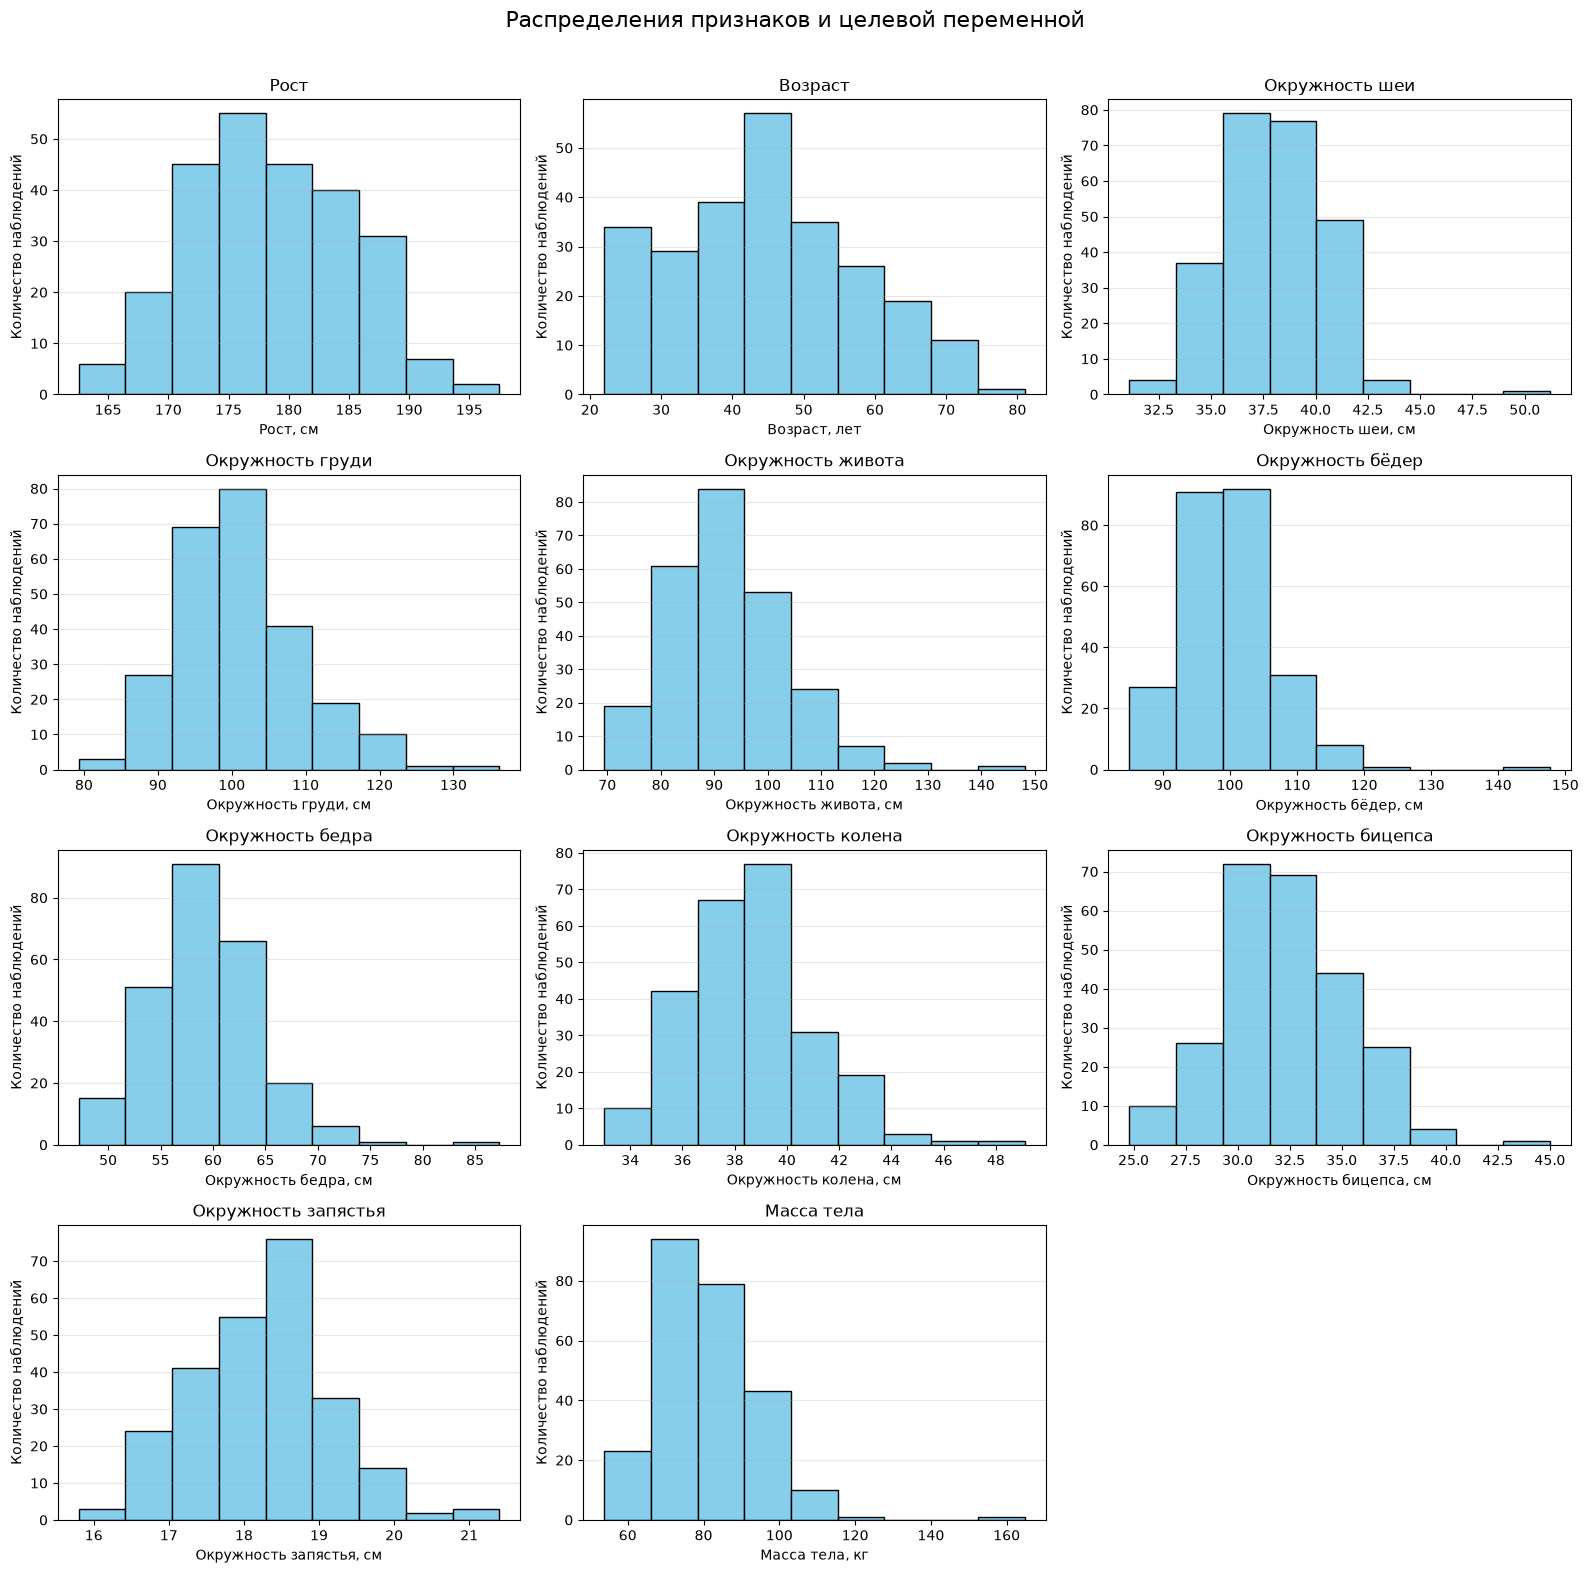

In [6]:
fig, axes = plt.subplots(4, 3, figsize=(16, 16))
axes = axes.ravel()

for ax, column in zip(axes, df.columns):
    ax.hist(
        df[column].dropna(),
        bins="sturges",
        edgecolor="black",
        color="skyblue"
    )

    ax.set_title(column)

    if column == "Возраст":
        unit = "лет"
    elif column == "Масса тела":
        unit = "кг"
    else:
        unit = "см"

    ax.set_xlabel(f"{column}, {unit}")
    ax.set_ylabel("Количество наблюдений")
    ax.grid(axis="y", alpha=0.3)

for ax in axes[len(df.columns):]:
    ax.set_visible(False)

fig.suptitle("Распределения признаков и целевой переменной", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

Анализ гистограмм показал, что распределения большинства антропометрических признаков визуально напоминают нормальное распределение: они имеют один выраженный пик с концентрацией наблюдений в центральной области. Для массы тела, окружностей груди, живота, бёдер, бедра, колена и бицепса заметна правосторонняя асимметрия. После удаления подозрительной записи аномально низкое значение роста 74,93 см на графике отсутствует. При этом сохраняются отдельные высокие значения окружности шеи 51,2 см, живота 148,1 см, бёдер 147,7 см, бедра 87,3 см, колена 49,1 см, бицепса 45,0 см и массы тела 164,72 кг.

### Корреляционный анализ и оценка мультиколлинеарности

Для исследования взаимосвязей между переменными построена корреляционная матрица с использованием коэффициента корреляции Пирсона.

<Axes: >

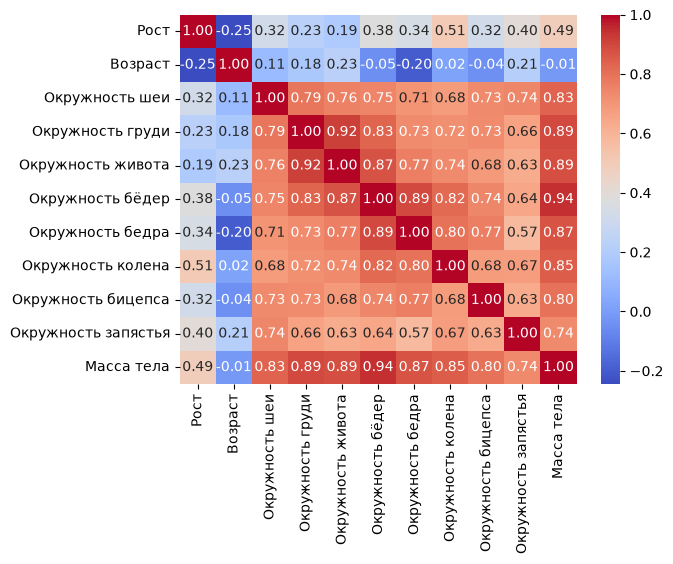

In [7]:
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")

Корреляционный анализ очищенного набора показал сильную положительную связь массы тела с большинством антропометрических признаков. Наиболее высокие коэффициенты корреляции получены для окружностей бёдер (r = 0,94), груди (r = 0,89), живота (r = 0,89) и бедра (r = 0,87). Корреляция массы тела с ростом составляет r = 0,49, а с возрастом практически отсутствует (r = -0,01).

Между независимыми переменными также обнаружены высокие корреляции: между окружностями груди и живота r = 0,92, бёдер и бедра r = 0,89, живота и бёдер r = 0,87. Такие связи указывают на возможную мультиколлинеарность, которая может снижать устойчивость оценок коэффициентов регрессии.

Для количественной оценки мультиколлинеарности рассчитаны коэффициенты инфляции дисперсии (VIF) для всех независимых переменных. Расчёт выполнялся путём построения вспомогательной линейной регрессии для каждого признака с использованием остальных признаков в качестве предикторов.

In [8]:
X = df.drop(columns=["Масса тела"])

results = []

for column in X.columns:
    other_features = X.drop(columns=[column])
    feature = X[column]

    model = LinearRegression()
    model.fit(other_features, feature)

    r_squared = model.score(other_features, feature)
    vif = 1 / (1 - r_squared) if r_squared < 1 else float("inf")

    results.append({
        "Признак": column,
        "R²": r_squared,
        "VIF": vif
    })

pd.DataFrame(results)

,Признак,R²,VIF
0,Рост,0.429602,1.753162
1,Возраст,0.518920,2.078654
2,Окружность шеи,0.742165,3.878454
3,Окружность груди,0.870480,7.720800
4,Окружность живота,0.912789,11.466442
5,Окружность бёдер,0.905907,10.627747
6,Окружность бедра,0.870492,7.721553
7,Окружность колена,0.777348,4.491306
8,Окружность бицепса,0.685944,3.184143
9,Окружность запястья,0.662465,2.962654


Расчёт VIF подтвердил наличие выраженной мультиколлинеарности. Наибольшие значения получены для окружности живота (11,47) и окружности бёдер (10,63): они превышают условный порог 10. Для окружностей груди и бедра VIF составляет примерно 7,72 и превышает условный порог 5, что также указывает на повышенную линейную зависимость от остальных признаков. Для остальных независимых переменных VIF меньше 5.

## Построение регрессионных моделей

Линейная регрессия определяет коэффициенты путём минимизации суммы квадратов ошибок. Гребневая регрессия дополнительно использует L2-регуляризацию, штрафующую большие значения коэффициентов и повышающую их устойчивость при мультиколлинеарности. Lasso использует L1-регуляризацию, которая может обнулять отдельные коэффициенты и тем самым выполнять отбор признаков.

Для построения регрессионных моделей исходные данные разделены на независимые переменные и целевую переменную - массу тела. Затем выполнено случайное разбиение на обучающую (80%) и тестовую (20%) выборки, содержащие 200 и 51 наблюдение соответственно. Для обеспечения воспроизводимости результатов использован параметр random_state=42.

Перед обучением независимые признаки стандартизируются с помощью StandardScaler: из значений вычитается среднее и выполняется деление на стандартное отклонение. Стандартизация включена в конвейер Pipeline, поэтому её параметры определяются только по обучающей части соответствующего разбиения. Тестовая и валидационная выборки преобразуются с использованием этих параметров.

Для оценки моделей применяется пятикратная кросс-валидация. Для гребневой регрессии и Lasso с помощью GridSearchCV подбирается параметр регуляризации alpha. Критерием выбора является минимальная средняя RMSE на валидационных частях обучающей выборки.

Дополнительно рассчитано стандартное отклонение коэффициента $R^2$ по пяти разбиениям кросс-валидации. Оно характеризует изменчивость качества модели в зависимости от состава обучающей и валидационной частей. Меньшее стандартное отклонение соответствует более стабильным результатам на рассмотренных разбиениях.

In [9]:
X = df.drop(columns=["Масса тела"])
y = df["Масса тела"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

cv = KFold(n_splits=5, shuffle=True, random_state=42)

linear_search = GridSearchCV(
    estimator=make_pipeline(
        StandardScaler(),
        LinearRegression()
    ),
    param_grid={},
    scoring={
        "RMSE": "neg_root_mean_squared_error",
        "R²": "r2",
        "MAPE": "neg_mean_absolute_percentage_error"
    },
    refit="RMSE",
    cv=cv
)

ridge_search = GridSearchCV(
    estimator=make_pipeline(
        StandardScaler(),
        Ridge()
    ),
    param_grid={
        "ridge__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000]
    },
    scoring={
        "RMSE": "neg_root_mean_squared_error",
        "R²": "r2",
        "MAPE": "neg_mean_absolute_percentage_error"
    },
    refit="RMSE",
    cv=cv
)

lasso_search = GridSearchCV(
    estimator=make_pipeline(
        StandardScaler(),
        Lasso(max_iter=10000)
    ),
    param_grid={
        "lasso__alpha": [0.0001, 0.001, 0.01, 0.1, 1, 10]
    },
    scoring={
        "RMSE": "neg_root_mean_squared_error",
        "R²": "r2",
        "MAPE": "neg_mean_absolute_percentage_error"
    },
    refit="RMSE",
    cv=cv
)

linear_search.fit(X_train, y_train)
ridge_search.fit(X_train, y_train)
lasso_search.fit(X_train, y_train)

linear_model = linear_search.best_estimator_
ridge_model = ridge_search.best_estimator_
lasso_model = lasso_search.best_estimator_

results = []

for name, search, alpha_parameter in [
    ("Линейная", linear_search, None),
    ("Гребневая", ridge_search, "ridge__alpha"),
    ("Lasso", lasso_search, "lasso__alpha")
]:
    index = search.best_index_

    results.append({
        "Модель": name,
        "alpha": (
            search.best_params_[alpha_parameter]
            if alpha_parameter is not None
            else np.nan
        ),
        "CV RMSE, кг":
            -search.cv_results_["mean_test_RMSE"][index],
        "CV R²":
            search.cv_results_["mean_test_R²"][index],
        "Стандартное отклонение CV R²":
            search.cv_results_["std_test_R²"][index],    
        "CV MAPE, %":
            -search.cv_results_["mean_test_MAPE"][index] * 100
    })

cv_summary = pd.DataFrame(results)
display(cv_summary.round(4))

,Модель,alpha,"CV RMSE, кг",CV R²,Стандартное отклонение CV R²,"CV MAPE, %"
0,Линейная,NaN,1.9254,0.9753,0.0043,1.8870
1,Гребневая,1.0000,1.9203,0.9754,0.0043,1.8866
2,Lasso,0.0001,1.9254,0.9753,0.0043,1.8870


По результатам подбора для гребневой регрессии выбрано alpha = 1,0, для Lasso - alpha = 0,0001. Эти значения обеспечили минимальную среднюю RMSE среди проверенных вариантов.

Наилучшие средние показатели кросс-валидации получены для гребневой регрессии: RMSE = 1,9203 кг, $R^2$ = 0,9754 и MAPE = 1,8866%. Линейная регрессия и Lasso показали практически одинаковые результаты: RMSE = 1,9254 кг, $R^2$ = 0,9753 и MAPE = 1,8870%. Очень малое значение alpha у Lasso означает слабую регуляризацию, что согласуется с близостью её результатов к обычной линейной регрессии.

Различия между моделями невелики. Результаты кросс-валидации использованы для выбора параметра alpha. После подбора модель обучена на всей обучающей выборке, а окончательная оценка качества выполнена на отдельной тестовой выборке, не участвовавшей в обучении и подборе параметров.

Стандартное отклонение $R^2$ по пяти разбиениям составляет около 0,0043 для всех трёх моделей. Небольшой разброс при среднем $R^2$ около 0,975 свидетельствует о высоком и стабильном качестве прогнозирования на рассмотренных разбиениях. По этому показателю существенных различий между моделями не выявлено.

После обучения проведена оценка моделей на тестовой выборке, содержащей 51 наблюдение и не участвовавшей в подборе параметров. Для каждой модели рассчитаны RMSE, $R^2$ и MAPE.

In [10]:
y_pred_linear = linear_model.predict(X_test)
y_pred_ridge = ridge_model.predict(X_test)
y_pred_lasso = lasso_model.predict(X_test)

results = []

for name, prediction in [
    ("Линейная", y_pred_linear),
    ("Гребневая", y_pred_ridge),
    ("Lasso", y_pred_lasso)
]:
    rmse = np.sqrt(mean_squared_error(y_test, prediction))
    r_squared = r2_score(y_test, prediction)

    mape = (
        mean_absolute_percentage_error(y_test, prediction) * 100
        if (y_test != 0).all()
        else np.nan
    )

    results.append({
        "Модель": name,
        "RMSE": rmse,
        "R²": r_squared,
        "MAPE, %": mape
    })

pd.DataFrame(results)

,Модель,RMSE,R²,"MAPE, %"
0,Линейная,3.059207,0.963472,1.949778
1,Гребневая,3.060161,0.963449,1.953337
2,Lasso,3.059220,0.963471,1.949787


На тестовой выборке линейная регрессия показала RMSE = 3,0592 кг, $R^2$ = 0,9635 и MAPE = 1,9498%. Результаты Lasso практически совпадают с результатами линейной регрессии. Для гребневой регрессии получены RMSE = 3,0602 кг, $R^2$ = 0,9634 и MAPE = 1,9533%.

По неокруглённым значениям всех трёх метрик небольшое преимущество имеет линейная регрессия, однако различия между моделями крайне малы.

По сравнению со средними результатами кросс-валидации на тестовой выборке RMSE увеличилась, а $R^2$ снизился. Это может быть связано с составом тестовой выборки и наличием отдельных наблюдений с большими ошибками прогнозирования.

Для наглядной оценки качества прогнозирования построены диаграммы рассеяния, отражающие зависимость предсказанных значений массы тела от фактических значений на тестовой выборке для трёх моделей: линейной, гребневой и Lasso-регрессии.

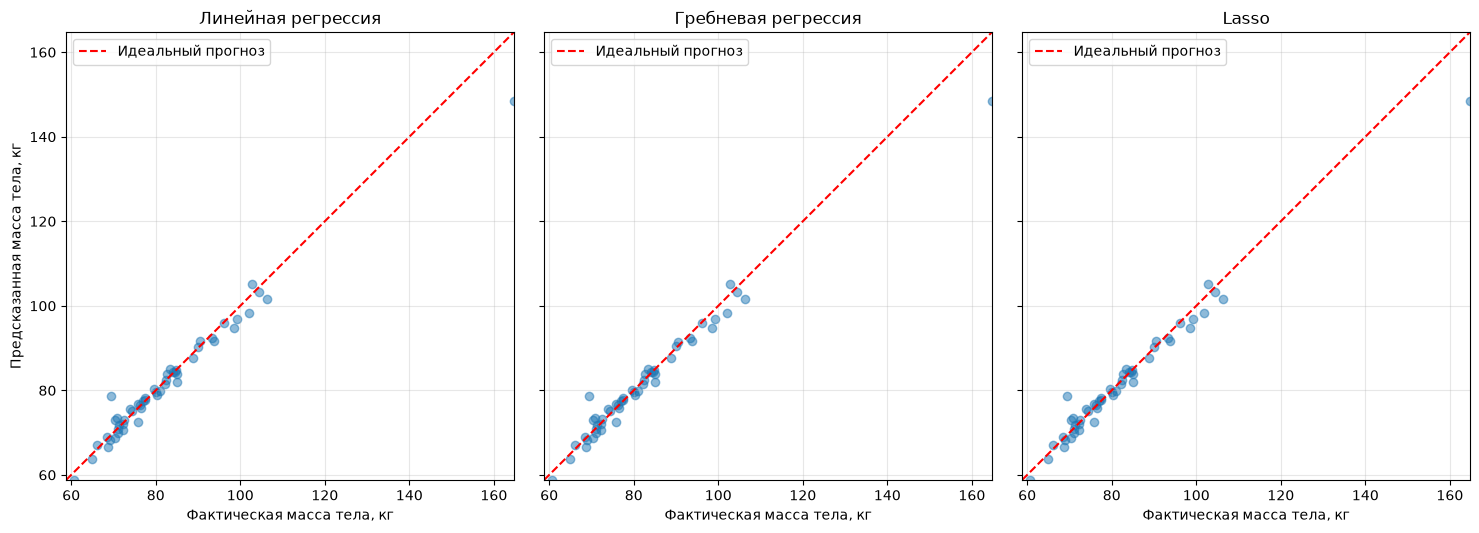

In [11]:
y_pred_linear = linear_model.predict(X_test)
y_pred_ridge = ridge_model.predict(X_test)
y_pred_lasso = lasso_model.predict(X_test)

lower = min(
    y_test.min(),
    y_pred_linear.min(),
    y_pred_ridge.min(),
    y_pred_lasso.min()
)
upper = max(
    y_test.max(),
    y_pred_linear.max(),
    y_pred_ridge.max(),
    y_pred_lasso.max()
)

fig, axes = plt.subplots(
    1, 3, figsize=(15, 5), sharex=True, sharey=True
)

for ax, prediction, title in [
    (axes[0], y_pred_linear, "Линейная регрессия"),
    (axes[1], y_pred_ridge, "Гребневая регрессия"),
    (axes[2], y_pred_lasso, "Lasso")
]:
    ax.scatter(y_test, prediction, alpha=0.5)

    ax.plot(
        [lower, upper], [lower, upper],
        "r--", label="Идеальный прогноз"
    )

    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(title)
    ax.set_xlabel("Фактическая масса тела, кг")
    ax.legend()
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Предсказанная масса тела, кг")

plt.tight_layout()
plt.show()

На графиках проведена линия идеального прогноза y = x. Большинство точек располагается близко к ней, что согласуется с высокими значениями $R^2$. При этом имеются отдельные заметные отклонения, в частности недооценка массы наиболее тяжёлого участника.

Графики трёх моделей практически совпадают, что соответствует близким значениям RMSE, $R^2$ и MAPE. Модели хорошо описывают зависимость массы тела от выбранных признаков для большинства тестовых наблюдений, однако отдельные большие ошибки требуют рассмотрения графиков остатков.

Для исследования структуры ошибок прогнозирования построены графики остатков линейной, гребневой и Lasso-регрессии. Остатки рассчитаны как разность между фактическими и предсказанными значениями массы тела. На графиках проведена горизонтальная линия на уровне 0, соответствующая отсутствию ошибки прогнозирования.

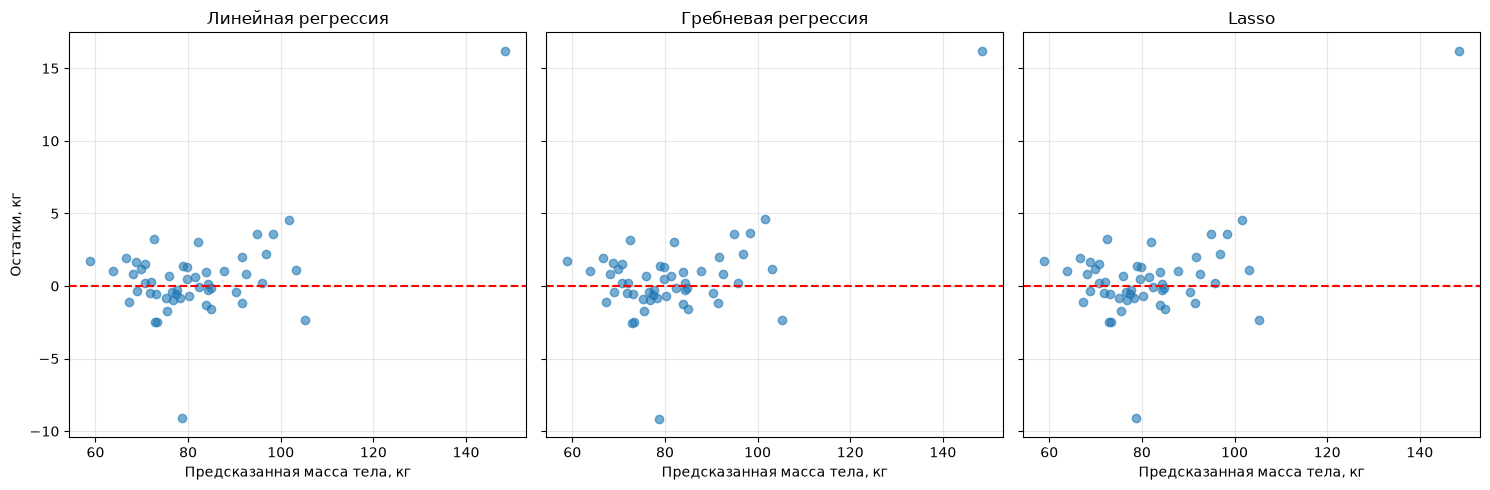

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, prediction, title in [
    (axes[0], y_pred_linear, "Линейная регрессия"),
    (axes[1], y_pred_ridge, "Гребневая регрессия"),
    (axes[2], y_pred_lasso, "Lasso")
]:
    residuals = y_test.to_numpy() - prediction

    ax.scatter(prediction, residuals, alpha=0.6)
    ax.axhline(0, color="red", linestyle="--")

    ax.set_title(title)
    ax.set_xlabel("Предсказанная масса тела, кг")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Остатки, кг")

plt.tight_layout()
plt.show()

Для всех трёх моделей большинство остатков располагается вокруг нулевой линии, преимущественно в диапазоне от -3 до +5 кг. Наблюдаются два заметных отклонения: положительный остаток около +16 кг при наибольшей предсказанной массе и отрицательный остаток около -9 кг при предсказанной массе около 79 кг. Положительный остаток означает недооценку фактической массы, отрицательный - её переоценку. Структура остатков у трёх моделей практически одинакова.

Визуальный анализ скорее указывает на приблизительную гомоскедастичность: в области большинства наблюдений разброс остатков относительно постоянен, выраженная воронкообразная структура отсутствует. Однако отдельные большие отклонения и малое количество наблюдений при высокой массе тела не позволяют уверенно распространить этот вывод на весь диапазон предсказаний.

## Метод главных компонент и повторное обучение моделей

Для снижения размерности пространства признаков и устранения мультиколлинеарности применён метод главных компонент (PCA). Предварительно выполнена стандартизация независимых переменных, после чего построена ковариационная матрица и рассчитаны её собственные значения и собственные векторы.

In [13]:
scaler_pca = StandardScaler()

X_train_scaled = scaler_pca.fit_transform(X_train)
X_test_scaled = scaler_pca.transform(X_test)

cov_matrix = np.cov(X_train_scaled, rowvar=False)

eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

order = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

variance_ratio = eigenvalues / eigenvalues.sum()
cumulative_ratio = np.cumsum(variance_ratio)

Выполнена стандартизация независимых признаков по обучающей выборке. По ковариационной матрице стандартизированных данных рассчитаны собственные значения и собственные векторы. Собственные значения упорядочены по убыванию, определены доли объяснённой дисперсии. Далее результаты представлены графически для выбора количества компонент.

Для анализа вклада главных компонент построен график каменистой осыпи, отражающий изменение собственных значений ковариационной матрицы стандартизированных признаков в зависимости от номера компоненты.

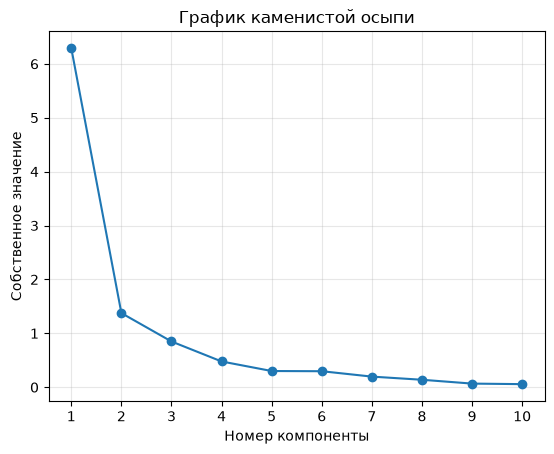

In [14]:
numbers = range(1, len(eigenvalues) + 1)

plt.plot(numbers, eigenvalues, "o-")
plt.xticks(numbers)
plt.xlabel("Номер компоненты")
plt.ylabel("Собственное значение")
plt.title("График каменистой осыпи")
plt.grid(alpha=0.3)
plt.show()

Наибольшее снижение собственного значения наблюдается между первой и второй компонентами. Далее вклад компонент уменьшается, а начиная примерно с пятой компоненты кривая становится более пологой.

Для дополнительного обоснования выбора количества главных компонент построен график накопленной доли объяснённой дисперсии. На графике отмечены пороговые значения 90% и 95%, позволяющие определить минимальное количество компонент, необходимое для сохранения заданной доли изменчивости исходных признаков.

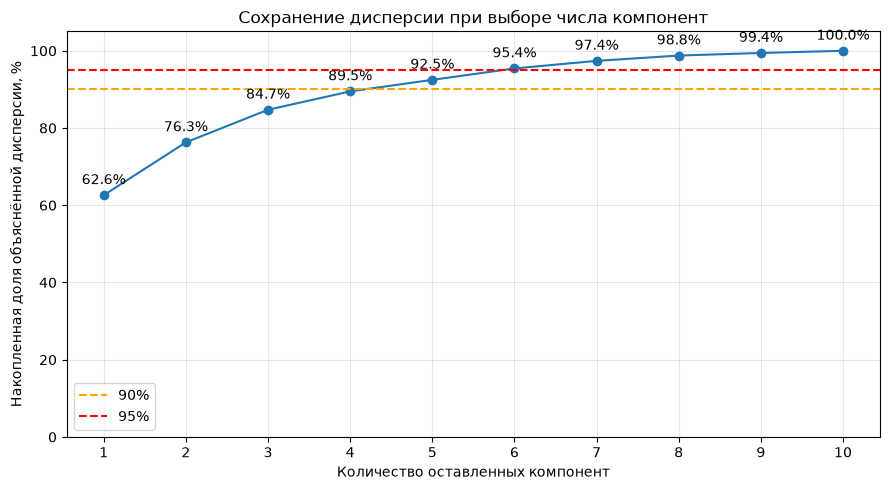

In [15]:
cumulative_variance = np.cumsum(variance_ratio) * 100
numbers = np.arange(1, len(variance_ratio) + 1)

plt.figure(figsize=(9, 5))

plt.plot(numbers, cumulative_variance, "o-")

for k, percent in zip(numbers, cumulative_variance):
    plt.annotate(
        f"{percent:.1f}%",
        (k, percent),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

plt.axhline(90, color="orange", linestyle="--", label="90%")
plt.axhline(95, color="red", linestyle="--", label="95%")

plt.xticks(numbers)
plt.ylim(0, 105)
plt.xlabel("Количество оставленных компонент")
plt.ylabel("Накопленная доля объяснённой дисперсии, %")
plt.title("Сохранение дисперсии при выборе числа компонент")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Четыре главные компоненты сохраняют 89,5% дисперсии стандартизированных признаков обучающей выборки. Шесть компонент сохраняют 95,4% дисперсии. Поэтому для дальнейшего моделирования оставлены шесть главных компонент: это минимальное количество, позволяющее сохранить не менее 95% дисперсии и сократить размерность пространства признаков с 10 до 6.

Проведена пятикратная кросс-валидация. На каждом разбиении стандартизация, ковариационная матрица и собственные векторы рассчитываются только по обучающей части. Валидационная часть преобразуется с использованием полученных параметров. Число компонент на всех разбиениях фиксировано и равно шести.

Для гребневой регрессии и Lasso используются значения alpha = 1,0 и alpha = 0,0001 соответственно, ранее подобранные для исходных признаков. Это позволяет сравнивать модели при одинаковых параметрах регуляризации.

In [16]:
best_ridge_alpha = ridge_search.best_params_["ridge__alpha"]
best_lasso_alpha = lasso_search.best_params_["lasso__alpha"]

k = 6

cv_pca_results = []

for fold, (train_indices, validation_indices) in enumerate(
    cv.split(X_train), start=1
):
    X_fold_train = X_train.iloc[train_indices]
    y_fold_train = y_train.iloc[train_indices]

    X_fold_validation = X_train.iloc[validation_indices]
    y_fold_validation = y_train.iloc[validation_indices]

    fold_scaler = StandardScaler()

    train_scaled = fold_scaler.fit_transform(X_fold_train)
    validation_scaled = fold_scaler.transform(X_fold_validation)

    fold_cov = np.cov(train_scaled, rowvar=False)

    values, vectors = np.linalg.eigh(fold_cov)
    order = np.argsort(values)[::-1]
    W_fold = vectors[:, order][:, :k]

    train_pca = train_scaled @ W_fold
    validation_pca = validation_scaled @ W_fold

    for name, model in [
        ("Линейная", LinearRegression()),
        ("Гребневая", Ridge(alpha=best_ridge_alpha)),
        ("Lasso", Lasso(
            alpha=best_lasso_alpha,
            max_iter=10000
        ))
    ]:
        model.fit(train_pca, y_fold_train)
        prediction = model.predict(validation_pca)

        actual = y_fold_validation.to_numpy()
        mask = actual != 0

        cv_pca_results.append({
            "Разбиение": fold,
            "Модель": name,
            "RMSE": np.sqrt(
                mean_squared_error(actual, prediction)
            ),
            "R²": r2_score(actual, prediction),
            "MAPE по ненулевым, %":
                mean_absolute_percentage_error(
                    actual[mask], prediction[mask]
                ) * 100 if mask.any() else np.nan
        })

cv_pca_table = pd.DataFrame(cv_pca_results)

display(cv_pca_table.round(4))

cv_pca_summary = cv_pca_table.groupby("Модель").agg(
    RMSE_mean=("RMSE", "mean"),
    R2_mean=("R²", "mean"),
    R2_std=("R²", lambda values: values.std(ddof=0)),
    MAPE_mean=("MAPE по ненулевым, %", "mean")
)

cv_pca_summary.columns = [
    "Средняя RMSE, кг",
    "Среднее R²",
    "Стандартное отклонение R²",
    "Средняя MAPE, %"
]

display(cv_pca_summary.round(4))

,Разбиение,Модель,RMSE,R²,"MAPE по ненулевым, %"
0,1,Линейная,1.8222,0.9733,1.8187
1,1,Гребневая,1.8261,0.9732,1.8207
2,1,Lasso,1.8223,0.9733,1.8188
3,2,Линейная,2.1077,0.9707,2.0448
4,2,Гребневая,2.1104,0.9707,2.0483
5,2,Lasso,2.1077,0.9707,2.0448
6,3,Линейная,1.7709,0.9796,1.6633
7,3,Гребневая,1.7650,0.9797,1.6520
8,3,Lasso,1.7708,0.9796,1.6632
9,4,Линейная,2.2696,0.9651,2.1919


,"Средняя RMSE, кг",Среднее R²,Стандартное отклонение R²,"Средняя MAPE, %"
Модель,,,,
Lasso,2.0145,0.973,0.0049,1.9719
Гребневая,2.0143,0.973,0.0049,1.9709
Линейная,2.0145,0.973,0.0049,1.9719


После PCA средние результаты трёх моделей практически совпадают. Для гребневой регрессии получены RMSE = 2,0143 кг, $R^2$ = 0,9730 и MAPE = 1,9709%. Для линейной регрессии и Lasso средняя RMSE составляет 2,0145 кг, $R^2$ = 0,9730, MAPE = 1,9719%.

По сравнению с кросс-валидацией на исходных признаках средняя RMSE и MAPE увеличились, а $R^2$ снизился для всех трёх моделей. Следовательно, в данном эксперименте сокращение числа признаков до шести не улучшило средние показатели кросс-валидации.

После применения PCA стандартное отклонение $R^2$ составляет около 0,0049 для всех трёх моделей при среднем значении около 0,9730. Результаты остаются стабильными, однако по сравнению с исходными признаками средний $R^2$ немного снизился, а его стандартное отклонение увеличилось с 0,0043 до 0,0049. Следовательно, применение PCA не улучшило ни среднее качество, ни стабильность результатов по $R^2$ на рассмотренных разбиениях.

Для проверки устранения мультиколлинеарности исходные независимые переменные преобразованы в шесть главных компонент, после чего построена их корреляционная матрица.

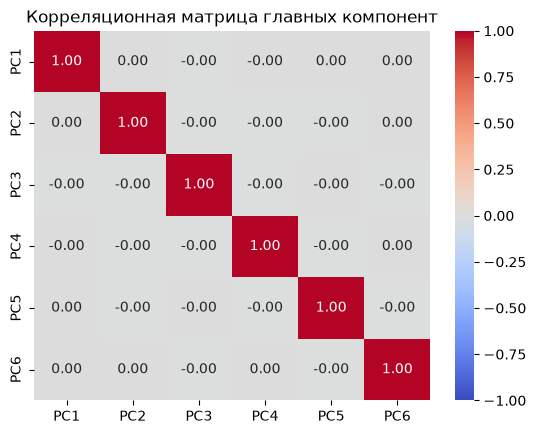

In [17]:
W = eigenvectors[:, :k]

X_train_pca = X_train_scaled @ W
X_test_pca = X_test_scaled @ W

components = pd.DataFrame(
    X_train_pca,
    columns=[f"PC{i + 1}" for i in range(k)]
)

sns.heatmap(
    components.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Корреляционная матрица главных компонент")
plt.show()

Коэффициенты корреляции между различными главными компонентами на обучающей выборке практически равны нулю, а на главной диагонали равны единице. 
PCA позволил устранить мультиколлинеарность в пространстве используемых компонент и сократить размерность с 10 до 6, сохранив 95,43% дисперсии стандартизированных признаков обучающей выборки.

Построена карта весов исходных стандартизированных признаков в шести главных компонентах. Значения представляют коэффициенты линейных комбинаций, формирующих компоненты. Чем больше абсолютная величина веса, тем сильнее соответствующий признак участвует в формировании компоненты. Признаки с весами одинакового знака входят в компоненту в одном направлении, а с противоположными знаками - в противоположных направлениях.

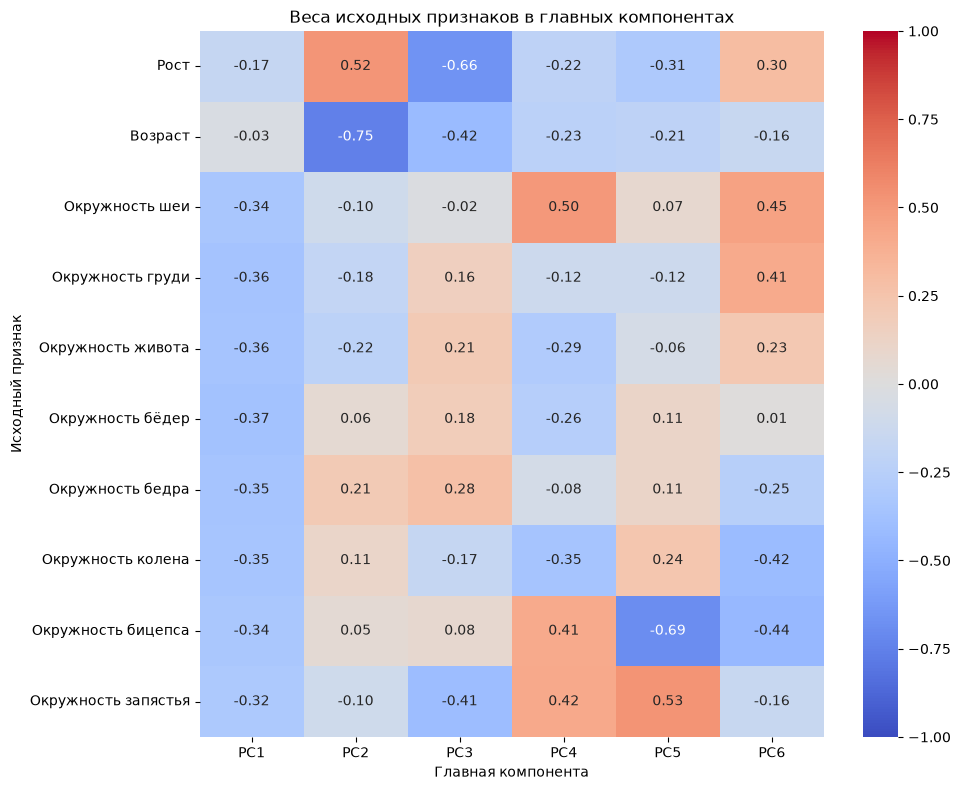

In [18]:
weights = pd.DataFrame(
    W,
    index=X_train.columns,
    columns=[f"PC{i + 1}" for i in range(k)]
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    weights,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Веса исходных признаков в главных компонентах")
plt.xlabel("Главная компонента")
plt.ylabel("Исходный признак")
plt.tight_layout()
plt.show()

Первая главная компонента формируется преимущественно окружностями различных частей тела. Наибольшие по модулю веса имеют окружности бёдер (-0,37), груди и живота (-0,36), бедра и колена (-0,35). Веса всех окружностей близки по величине и имеют одинаковый знак, поэтому первую компоненту можно интерпретировать как общую характеристику поперечных размеров тела. Возраст участвует в её формировании с небольшим весом (-0,03).
Во второй компоненте преобладают возраст (-0,75) и рост (0,52), входящие с противоположными знаками. В отличие от первой, эта компонента отражает преимущественно сочетание возрастных различий и различий в росте: более высокие её значения соответствуют большему росту и меньшему возрасту при фиксированных остальных признаках.
Последующие компоненты отражают более частные сочетания антропометрических характеристик. Например, в пятой компоненте наиболее выражено противопоставление окружностей бицепса (-0,69) и запястья (0,53).

In [19]:
linear_pca = LinearRegression()
ridge_pca = Ridge(alpha=best_ridge_alpha)
lasso_pca = Lasso(
    alpha=best_lasso_alpha,
    max_iter=10000
)

linear_pca.fit(X_train_pca, y_train)
ridge_pca.fit(X_train_pca, y_train)
lasso_pca.fit(X_train_pca, y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",0.0001
,"max_iter max_iter: int, default=1000The maximum number of iterations.",10000
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


На полной обучающей выборке обучены линейная, гребневая и Lasso-регрессия. Для гребневой регрессии использовано alpha = 1,0, для Lasso - alpha = 0,0001.

Для оценки влияния метода главных компонент на качество прогнозирования проведено сравнение регрессионных моделей, обученных на исходных признаках и на шести главных компонентах. Оценка выполнена на одинаковой тестовой выборке с использованием метрик RMSE, $R^2$ и MAPE.

In [20]:
mask = y_test.to_numpy() != 0

models = [
    ("Линейная", "Исходные признаки", linear_model, X_test),
    ("Гребневая", "Исходные признаки", ridge_model, X_test),
    ("Lasso", "Исходные признаки", lasso_model, X_test),

    ("Линейная", "PCA", linear_pca, X_test_pca),
    ("Гребневая", "PCA", ridge_pca, X_test_pca),
    ("Lasso", "PCA", lasso_pca, X_test_pca)
]

results = []

for name, features, model, test_data in models:
    prediction = model.predict(test_data)

    results.append({
        "Модель": name,
        "Признаки": features,
        "RMSE": np.sqrt(mean_squared_error(y_test, prediction)),
        "R²": r2_score(y_test, prediction),
        "MAPE по ненулевым, %":
            mean_absolute_percentage_error(
                y_test.to_numpy()[mask],
                prediction[mask]
            ) * 100 if mask.any() else np.nan
    })

comparison = pd.DataFrame(results)
display(comparison.round(4))

,Модель,Признаки,RMSE,R²,"MAPE по ненулевым, %"
0,Линейная,Исходные признаки,3.0592,0.9635,1.9498
1,Гребневая,Исходные признаки,3.0602,0.9634,1.9533
2,Lasso,Исходные признаки,3.0592,0.9635,1.9498
3,Линейная,PCA,2.9565,0.9659,2.0678
4,Гребневая,PCA,2.9628,0.9657,2.0669
5,Lasso,PCA,2.9566,0.9659,2.0678


На тестовой выборке применение PCA привело к снижению RMSE и увеличению $R^2$ для всех трёх моделей. Для линейной регрессии RMSE уменьшилась с 3,0592 до 2,9565 кг, для гребневой - с 3,0602 до 2,9628 кг, для Lasso - с 3,0592 до 2,9566 кг. Значения $R^2$ увеличились примерно с 0,9635 до 0,9659 для линейной регрессии и Lasso и с 0,9634 до 0,9657 для гребневой регрессии.

Одновременно MAPE увеличилась: для линейной регрессии и Lasso - с 1,9498% до 2,0678%, для гребневой - с 1,9533% до 2,0669%. Следовательно, PCA улучшил качество по RMSE и $R^2$ , но ухудшил его по средней абсолютной процентной ошибке.

Разнонаправленное изменение метрик объясняется тем, что они по-разному оценивают ошибки: RMSE сильнее учитывает большие абсолютные отклонения, а MAPE - относительные ошибки каждого наблюдения. Наименьшая тестовая RMSE получена для линейной регрессии после PCA - 2,9565 кг. Наименьшая MAPE получена для линейной регрессии на исходных признаках - 1,9498%; результат Lasso практически совпадает с ней.

Таким образом, PCA сократил количество признаков и устранил мультиколлинеарность, однако не обеспечил улучшения всех показателей качества одновременно.

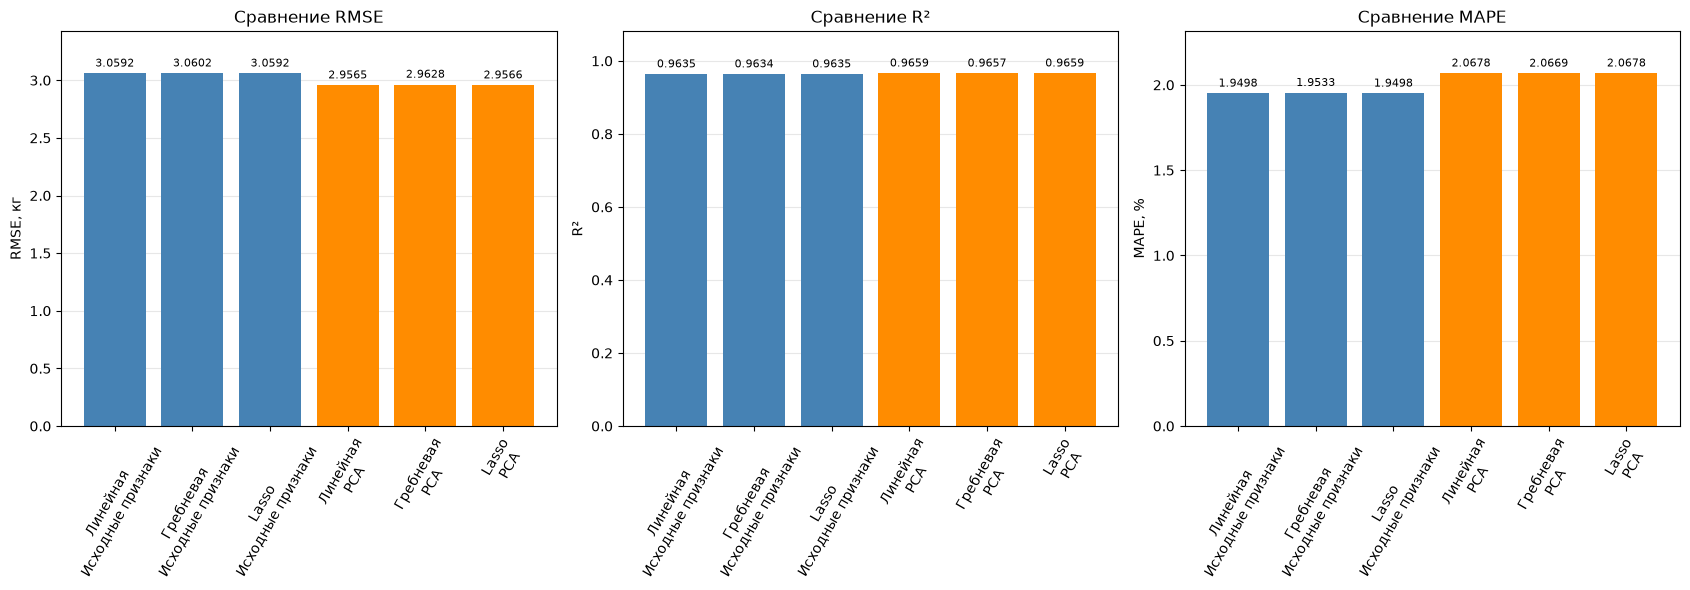

In [21]:
plot_data = comparison.copy()

plot_data["Вариант"] = (
    plot_data["Модель"] + "\n" + plot_data["Признаки"]
)

fig, axes = plt.subplots(1, 3, figsize=(17, 6))

colors = [
    "steelblue" if features == "Исходные признаки"
    else "darkorange"
    for features in plot_data["Признаки"]
]

for ax, metric, title, ylabel in [
    (axes[0], "RMSE", "Сравнение RMSE", "RMSE, кг"),
    (axes[1], "R²", "Сравнение R²", "R²"),
    (
        axes[2],
        "MAPE по ненулевым, %",
        "Сравнение MAPE",
        "MAPE, %"
    )
]:
    bars = ax.bar(
        plot_data["Вариант"],
        plot_data[metric],
        color=colors
    )

    ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=8)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, plot_data[metric].max() * 1.12)
    ax.tick_params(axis="x", labelrotation=60)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

На столбчатых диаграммах представлены метрики шести моделей на исходных признаках и после PCA. После преобразования признаков RMSE снизилась, а $R^2$ увеличился для всех трёх моделей, однако MAPE возросла. Различия между моделями внутри каждого набора признаков невелики. Таким образом, графики подтверждают, что применение PCA улучшило качество прогнозирования по RMSE и $R^2$, но ухудшило его по MAPE.

## Заключение

В ходе лабораторной работы проведены анализ и предобработка данных, исследованы распределения переменных и их корреляции. Исключено одно подозрительное наблюдение, после чего для моделирования использован набор из 251 записи. Расчёт VIF подтвердил наличие мультиколлинеарности между независимыми признаками.

Построены модели линейной, гребневой и Lasso-регрессии, проведены кросс-валидация и подбор параметров регуляризации. Метод PCA позволил сократить количество признаков с 10 до 6, сохранив 95,43% дисперсии стандартизированных признаков обучающей выборки и сформировав некоррелированные компоненты.

На тестовой выборке после PCA значения RMSE снизились, а R² увеличились для всех трёх моделей, однако MAPE выросла. Наименьшая RMSE получена для линейной регрессии после PCA: 2,9565 кг при R² = 0,9659. Результаты показали, что влияние снижения размерности на качество прогнозирования зависит от используемой метрики.